# Prostate Cancer Detection  Hybrid EfficientNet + GAT + GCN (IMPROVED v4 — LOCAL)
### Local PC Run — Conda + RTX 3060 12GB

---
**Architecture:** EfficientNet-B4 (CNN) + Graph Attention Network (GAT) + Graph Convolutional Network (GCN)  
**Working dir:** `<repo>\`  
**Dataset:** 6,002 balanced images (3,000 benign + 3,002 malignant)  
**Target:** AUC-ROC > 0.97, Accuracy > 96%

### Improvements over v1 (still all included):
> 1. **Stronger augmentation** — TrivialAugment + ColorJitter + RandomErasing
> 2. **SE-style attention fusion gate** — learnable branch weights
> 3. **Focal Loss** — for class-ambiguous MRI patches
> 4. **3-layer GCN** — richer multi-hop topology
> 5. **80 epochs, patience=15**
> 6. **Test-Time Augmentation (TTA)**
> 7. **Clean train metrics tracking** — train loss/acc measured in eval mode
> 8. **NaN-permanent-fix** — fp32 evaluation eliminates AMP overflow

### Local environment requirements:
```
Conda env with: torch, torchvision, timm, torch-geometric,
                scikit-learn, scikit-image, matplotlib, seaborn
GPU           : NVIDIA RTX 3060 12GB (CUDA 13.1)
Working dir   : <repo>\
Graph cache   : <repo>\graph_cache.pkl (already exists)
Dataset       : <repo>\dataset\Benign + Malignant
```


In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1B — Local PC Setup (RTX 3060 / Conda)                  ║
# ║   No Drive mount — uses <repo>\ directly           ║
# ╚══════════════════════════════════════════════════════════════╝
import os

# Root project directory on local disk
WORK_DIR   = os.path.join(REPO_ROOT, 'runs', 'hybrid')
# Source data lives in the original location
DATA_ROOT  = REPO_ROOT
DRIVE_ROOT = DATA_ROOT

assert os.path.isdir(WORK_DIR), f'Folder not found: {WORK_DIR}'
os.makedirs(WORK_DIR, exist_ok=True)

print('Work directory  :', WORK_DIR)
print('Files in folder :')
for f in sorted(os.listdir(WORK_DIR)):
    print('  •', f)


Work directory  : <repo>/results\Retrain
Files in folder :
  • .ipynb_checkpoints
  • Proposed Hybrid Prostate .ipynb


## CELL 1 — Install Libraries

In [2]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1C — Verify environment (Conda RTX 3060)                ║
# ║   Assumes you already installed in your conda env:           ║
# ║     torch, torchvision, timm, torch-geometric,               ║
# ║     scikit-learn, scikit-image, matplotlib, seaborn          ║
# ╚══════════════════════════════════════════════════════════════╝
import torch
print(f'PyTorch : {torch.__version__}')
print(f'CUDA    : {torch.version.cuda}')
print(f'GPU     : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT FOUND"}')
print(f'VRAM    : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB' if torch.cuda.is_available() else '')
print('Done!')


PyTorch : 2.5.1
CUDA    : 12.1
GPU     : NVIDIA GeForce RTX 3060
VRAM    : 12.9 GB
Done!


## CELL 2 — Mount Drive & Extract Dataset

In [3]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 2 — Local Dataset Setup                                  ║
# ║   Reads dataset from DATA_ROOT (<repo>/dataset)     ║
# ╚══════════════════════════════════════════════════════════════╝
import os, zipfile, shutil

DATA_DIR = os.path.join(DATA_ROOT, 'dataset')
ZIP_PATH = os.path.join(DATA_ROOT,
                        'manifest-gJIZVVFt6412408718812805737',
                        'Prostrain Cancer Dataset.zip')

if not os.path.exists(DATA_DIR):
    print('Extracting dataset from zip...')
    os.makedirs(DATA_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(DATA_DIR)
    nested = os.path.join(DATA_DIR, 'Prostrain Cancer Dataset')
    if os.path.exists(nested):
        for item in os.listdir(nested):
            shutil.move(os.path.join(nested, item), DATA_DIR)
        os.rmdir(nested)
    print('Extracted!')
else:
    print('Already extracted!')

benign    = os.listdir(os.path.join(DATA_DIR, 'Benign'))
malignant = os.listdir(os.path.join(DATA_DIR, 'Malignant'))
print(f'Benign    : {len(benign)}')
print(f'Malignant : {len(malignant)}')
print('Ready to train!')


Already extracted!
Benign    : 3000
Malignant : 3002
Ready to train!


## CELL 3 — All Imports & Settings

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, random, json, time
from pathlib import Path
from PIL import Image
from sklearn.metrics import (roc_auc_score, classification_report,
                              confusion_matrix, roc_curve)
from sklearn.neighbors import kneighbors_graph
from skimage.segmentation import slic

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import timm
from torch_geometric.nn import GATConv, GCNConv, global_mean_pool
from torch_geometric.data import Data, Batch

warnings.filterwarnings('ignore')

# ── Reproducibility ────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Hyperparameters (IMPROVED v2) ──────────────────────────
CONFIG = {
    'backbone'       : 'efficientnet_b4',
    'img_size'       : 224,
    'batch_size'     : 32,
    'num_epochs'     : 80,          
    'lr_backbone'    : 1e-4,
    'lr_head'        : 3e-4,
    'weight_decay'   : 1e-4,
    'hidden_dim'     : 256,
    'gat_heads'      : 4,
    'gcn_layers'     : 3,           
    'dropout'        : 0.4,         
    'focal_gamma'    : 2.0,        
    'focal_alpha'    : 0.75,        
    'n_superpixels'  : 75,
    'knn_k'          : 5,
    'train_split'    : 0.70,
    'val_split'      : 0.15,
    'test_split'     : 0.15,
    'seed'           : 42,
    'tta_n'          : 5,           
}
print(f'Device: {DEVICE}')
print(f'Config: {json.dumps(CONFIG, indent=2)}')


Device: cuda
Config: {
  "backbone": "efficientnet_b4",
  "img_size": 224,
  "batch_size": 32,
  "num_epochs": 80,
  "lr_backbone": 0.0001,
  "lr_head": 0.0003,
  "weight_decay": 0.0001,
  "hidden_dim": 256,
  "gat_heads": 4,
  "gcn_layers": 3,
  "dropout": 0.4,
  "focal_gamma": 2.0,
  "focal_alpha": 0.75,
  "n_superpixels": 75,
  "knn_k": 5,
  "train_split": 0.7,
  "val_split": 0.15,
  "test_split": 0.15,
  "seed": 42,
  "tta_n": 5
}


## PRE-BUILD ALL GRAPHS AND SAVE TO DISK

In [5]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ Graph cache - read from cache/ folder                           ║
# ╚══════════════════════════════════════════════════════════════╝
import pickle

GRAPH_CACHE_LOCAL = os.path.join(REPO_ROOT, 'cache', 'graph_cache.pkl')

if not os.path.exists(GRAPH_CACHE_LOCAL):
    raise FileNotFoundError(
        f'Graph cache not found at {GRAPH_CACHE_LOCAL}. '
        f'Run gnn_preprocessing_complete.py first to build it.'
    )

GRAPH_CACHE = GRAPH_CACHE_LOCAL
print(f'Graph cache found: {GRAPH_CACHE_LOCAL}')
print(f'Size: {os.path.getsize(GRAPH_CACHE_LOCAL)/1e6:.1f} MB')


Graph cache found: <repo>/cache\graph_cache.pkl
Size: 53.5 MB


## CELL 4 — Dataset with Strong Augmentation

In [6]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 4 — Datasets, DataLoaders & Graph Cache (IMPROVED v2)   ║
# ║ • Stronger augmentation: TrivialAugment + ColorJitter         ║
# ║   + RandomErasing → proven +1-2% over mild aug               ║
# ╚══════════════════════════════════════════════════════════════╝

import pickle

# ── Load pre-built graph cache ───────────────────────────────
GRAPH_CACHE_PATH = os.path.join(REPO_ROOT, 'cache', 'graph_cache.pkl')
print(f'Loading graph cache from {GRAPH_CACHE_PATH} ...')
with open(GRAPH_CACHE_PATH, 'rb') as f:
    GRAPH_CACHE = pickle.load(f)
print(f'Loaded {len(GRAPH_CACHE):,} cached graphs')


# ── Build file list ─────────────────────────────────────────
all_files = []
for label, folder in [(0, 'Benign'), (1, 'Malignant')]:
    folder_path = Path(DATA_DIR) / folder
    for f in folder_path.glob('*.jpg'):
        all_files.append((str(f), label))

random.seed(SEED)
random.shuffle(all_files)
n       = len(all_files)
n_train = int(n * CONFIG['train_split'])
n_val   = int(n * CONFIG['val_split'])

train_files = all_files[:n_train]
val_files   = all_files[n_train:n_train+n_val]
test_files  = all_files[n_train+n_val:]

print(f'Train : {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}')


# ── IMPROVED: Stronger augmentation for training ────────────
# TrivialAugment auto-selects magnitude → covers more visual variation
# ColorJitter handles scanner/staining variation in MRI
# RandomErasing simulates tissue occlusion/artifact
# Together these add ~1-2% accuracy over mild flip+rotation only
train_transform = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.3),
    T.RandomRotation(degrees=15),
    T.TrivialAugmentWide(),                         # NEW: auto magnitude
    T.ColorJitter(brightness=0.2, contrast=0.2,
                  saturation=0.1, hue=0.05),        # NEW: scanner variation
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.25, scale=(0.02, 0.1)),     # NEW: occlusion sim
])

val_transform = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
])

# ── TTA transform (5 slightly different views at inference) ─
tta_transforms = [
    T.Compose([
        T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]),
    T.Compose([
        T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        T.RandomHorizontalFlip(p=1.0),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]),
    T.Compose([
        T.Resize((int(CONFIG['img_size']*1.1), int(CONFIG['img_size']*1.1))),
        T.CenterCrop(CONFIG['img_size']),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]),
    T.Compose([
        T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        T.RandomRotation(degrees=(90,90)),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]),
    T.Compose([
        T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        T.RandomRotation(degrees=(180,180)),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]),
]


# ── Dataset class ───────────────────────────────────────────
class ProstateDataset(Dataset):
    def __init__(self, file_list, transform, build_graph=True, graph_cache=None):
        self.files       = file_list
        self.transform   = transform
        self.build_graph = build_graph
        self.graph_cache = graph_cache if graph_cache is not None else {}

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path, label = self.files[idx]
        img_pil     = Image.open(path).convert('RGB')
        img_tensor  = self.transform(img_pil)

        if self.build_graph and path in self.graph_cache:
            cached = self.graph_cache[path]
            graph = Data(
                x          = torch.tensor(cached['x'],          dtype=torch.float),
                edge_index = torch.tensor(cached['edge_index'], dtype=torch.long),
                y          = torch.tensor(label,                dtype=torch.long)
            )
        else:
            graph = None

        return img_tensor, torch.tensor(label, dtype=torch.long), graph


# ── MixUp ───────────────────────────────────────────────────
def mixup_data(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1
    idx = torch.randperm(x.size(0), device=x.device)
    mixed = lam * x + (1 - lam) * x[idx]
    return mixed, y, y[idx], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


# ── Custom collate for graph batching ───────────────────────
def collate_fn(batch):
    imgs   = torch.stack([b[0] for b in batch])
    labels = torch.stack([b[1] for b in batch])
    graphs = [b[2] for b in batch if b[2] is not None]
    graph_batch = Batch.from_data_list(graphs) if graphs else None
    return imgs, labels, graph_batch


# ── Create datasets ─────────────────────────────────────────
print('Creating datasets...')
train_ds = ProstateDataset(train_files, train_transform,
                           build_graph=True, graph_cache=GRAPH_CACHE)
val_ds   = ProstateDataset(val_files,   val_transform,
                           build_graph=True, graph_cache=GRAPH_CACHE)
test_ds  = ProstateDataset(test_files,  val_transform,
                           build_graph=True, graph_cache=GRAPH_CACHE)

sample_path = train_files[0][0]
print('✓ Cache hit confirmed' if sample_path in GRAPH_CACHE
      else '⚠ WARNING: First file NOT in cache!')

train_labels = [f[1] for f in train_files]
class_counts = np.bincount(train_labels)
weights      = 1.0 / class_counts[train_labels]
sampler      = WeightedRandomSampler(weights, len(weights), replacement=True)

train_dl = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                      sampler=sampler, num_workers=0,
                      pin_memory=False, collate_fn=collate_fn)
val_dl   = DataLoader(val_ds,   batch_size=CONFIG['batch_size'],
                      shuffle=False, num_workers=0,
                      pin_memory=False, collate_fn=collate_fn)
test_dl  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'],
                      shuffle=False, num_workers=0,
                      pin_memory=False, collate_fn=collate_fn)

print(f'Train batches : {len(train_dl)}')
print(f'Val batches   : {len(val_dl)}')
print(f'Test batches  : {len(test_dl)}')
print('Augmentation  : STRONG (TrivialAugment + ColorJitter + RandomErasing)')
print('Datasets ready!')


Loading graph cache from <repo>/cache\graph_cache.pkl ...
Loaded 6,002 cached graphs
Train : 4201 | Val: 900 | Test: 901
Creating datasets...
✓ Cache hit confirmed
Train batches : 132
Val batches   : 29
Test batches  : 29
Augmentation  : STRONG (TrivialAugment + ColorJitter + RandomErasing)
Datasets ready!


## CELL 5 — Hybrid EfficientNet + GAT + GCN Model

In [7]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 5 — Hybrid EfficientNet + GAT + GCN (IMPROVED v2)       ║
# ║ Key changes:                                                  ║
# ║   1. GCN: 3 layers instead of 2 (richer topology)            ║
# ║   2. SE Attention Fusion Gate instead of naive concat         ║
# ║      → model learns to weight branches per sample            ║
# ║   3. Bottleneck MLP in fusion (512→256→128) for regularisation║
# ╚══════════════════════════════════════════════════════════════╝

class HybridProstateCancerNet(nn.Module):
    """
    IMPROVED Triple-Branch Architecture v2:

    Branch 1 (CNN)  : EfficientNet-B4 → 512-dim
    Branch 2 (GAT)  : CNN features → long-range attention → 256-dim
    Branch 3 (GCN)  : SLIC superpixels → 3-layer GCN → 128-dim

    Fusion (NEW):     SE-style attention gate
      - Concat → [896-dim]
      - FC squeeze → 64-dim → sigmoid gate → re-weight each dim
      - Excitation gives each branch adaptive importance per sample

    Why SE fusion over plain concat?
      - GAT branch dominates on complex inter-region patterns
      - GCN branch dominates on local topology cues
      - CNN branch dominates on texture
      - SE gate lets the network learn WHICH branch to trust per image
    """

    def __init__(self, num_classes=2, hidden=256, gat_heads=4, dropout=0.4):
        super().__init__()
        H = hidden

        # ── Branch 1: EfficientNet CNN backbone ──────────────
        self.backbone = timm.create_model(
            'efficientnet_b4', pretrained=True,
            num_classes=0, global_pool='avg'
        )
        cnn_dim = self.backbone.num_features  # 1792

        # Freeze early layers, fine-tune last 3 blocks (was 2)
        blocks_to_freeze = ['blocks.0', 'blocks.1', 'blocks.2',
                            'blocks.3', 'conv_stem', 'bn1']
        for name, param in self.backbone.named_parameters():
            if any(b in name for b in blocks_to_freeze):
                param.requires_grad = False

        # CNN projection: 1792 → 512
        self.cnn_proj = nn.Sequential(
            nn.Linear(cnn_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5)
        )

        # ── Branch 2: GAT on CNN features ────────────────────
        self.gat_node_proj = nn.Sequential(
            nn.Linear(cnn_dim, H), nn.ReLU()
        )
        self.gat1 = GATConv(H, H // gat_heads, heads=gat_heads, dropout=0.2)
        self.gat2 = GATConv(H, H // gat_heads, heads=gat_heads, dropout=0.2)
        self.gat_norm1 = nn.LayerNorm(H)
        self.gat_norm2 = nn.LayerNorm(H)

        # ── Branch 3: DEEPER GCN (3 layers) ──────────────────
        # Extra layer = richer multi-hop neighbourhood aggregation
        # 8-dim SLIC features → H → H → H//2 → H//4
        self.gcn_input_proj = nn.Sequential(
            nn.Linear(8, H), nn.ReLU()
        )
        self.gcn1      = GCNConv(H,     H)
        self.gcn2      = GCNConv(H,     H // 2)
        self.gcn3      = GCNConv(H//2,  H // 4)  # NEW third layer
        self.gcn_norm1 = nn.LayerNorm(H)
        self.gcn_norm2 = nn.LayerNorm(H // 2)
        self.gcn_norm3 = nn.LayerNorm(H // 4)    # NEW

        # ── Fusion: SE Attention Gate + Classifier ───────────
        # 512 (CNN) + 256 (GAT) + 64 (GCN) = 832
        fusion_dim = 512 + H + H // 4

        # SE gate: squeeze → sigmoid → re-weight
        self.se_gate = nn.Sequential(
            nn.Linear(fusion_dim, fusion_dim // 8),  # squeeze
            nn.ReLU(),
            nn.Linear(fusion_dim // 8, fusion_dim),  # excite
            nn.Sigmoid()                             # gate in [0,1]
        )

        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout * 0.6),
            nn.Linear(128, num_classes)
        )

    def forward(self, imgs, graph_batch):
        B = imgs.size(0)

        # ── Branch 1: CNN ─────────────────────────────────────
        cnn_feats = self.backbone(imgs)          # (B, 1792)
        cnn_out   = self.cnn_proj(cnn_feats)     # (B, 512)

        # ── Branch 2: GAT ─────────────────────────────────────
        gat_nodes = self.gat_node_proj(cnn_feats)
        src = torch.arange(B, device=imgs.device).repeat_interleave(B)
        dst = torch.arange(B, device=imgs.device).repeat(B)
        mask   = src != dst
        ei_gat = torch.stack([src[mask], dst[mask]])
        bv_gat = torch.arange(B, device=imgs.device)

        x = self.gat_norm1(F.elu(self.gat1(gat_nodes, ei_gat)))
        x = self.gat_norm2(F.elu(self.gat2(x, ei_gat)))
        gat_out = global_mean_pool(x, bv_gat)    # (B, H=256)

        # ── Branch 3: 3-layer GCN ─────────────────────────────
        if graph_batch is not None:
            gx = self.gcn_input_proj(graph_batch.x)
            ei = graph_batch.edge_index
            gb = graph_batch.batch

            gx = self.gcn_norm1(F.relu(self.gcn1(gx, ei)))
            gx = self.gcn_norm2(F.relu(self.gcn2(gx, ei)))
            gx = self.gcn_norm3(F.relu(self.gcn3(gx, ei)))  # NEW
            gcn_out = global_mean_pool(gx, gb)               # (B, H//4=64)
        else:
            gcn_out = torch.zeros(B, self.gcn_norm3.normalized_shape[0],
                                  device=imgs.device)

        # ── SE-Gated Fusion ───────────────────────────────────
        fused  = torch.cat([cnn_out, gat_out, gcn_out], dim=1)  # (B, 832)
        gate   = self.se_gate(fused)                             # (B, 832)
        fused  = fused * gate                                    # re-weight

        return self.classifier(fused)


model = HybridProstateCancerNet(
    num_classes=2,
    hidden=CONFIG['hidden_dim'],
    gat_heads=CONFIG['gat_heads'],
    dropout=CONFIG['dropout']
).to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params     : {total_params:,}')
print(f'Trainable params : {trainable_params:,}')
print(f'Frozen params    : {total_params - trainable_params:,}')
print('Model ready!')


model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

Total params     : 19,838,130
Trainable params : 18,464,518
Frozen params    : 1,373,612
Model ready!


## CELL 6 — Training Setup (Optimized)

In [8]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6 — Training Setup (IMPROVED v2)                        ║
# ║   • Focal Loss (gamma=2) replaces CrossEntropy+LabelSmoothing ║
# ║     → down-weights easy samples, focuses on hard/ambiguous   ║
# ║   • Unfreeze one more backbone block (blocks.4 now trains)    ║
# ║   • T_mult=2 keeps restarts useful over 80 epochs            ║
# ╚══════════════════════════════════════════════════════════════╝

# ── Focal Loss implementation ────────────────────────────────
class FocalLoss(nn.Module):
    """
    Focal Loss = -alpha * (1-pt)^gamma * log(pt)
    gamma=2 : strong focus on misclassified samples
    alpha=0.75: slight up-weight for malignant class
    """
    def __init__(self, gamma=2.0, alpha=0.75, reduction='mean'):
        super().__init__()
        self.gamma     = gamma
        self.alpha     = alpha
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt      = torch.exp(-ce_loss)
        # alpha weighting: alpha for class=1, (1-alpha) for class=0
        alpha_t = torch.where(targets == 1,
                              torch.tensor(self.alpha,     device=inputs.device),
                              torch.tensor(1-self.alpha,   device=inputs.device))
        focal   = alpha_t * (1 - pt) ** self.gamma * ce_loss
        return focal.mean() if self.reduction == 'mean' else focal.sum()


# ── Differential learning rates ─────────────────────────────
backbone_params = [p for n, p in model.named_parameters()
                   if 'backbone' in n and p.requires_grad]
head_params     = [p for n, p in model.named_parameters()
                   if 'backbone' not in n and p.requires_grad]

optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': CONFIG['lr_backbone']},
    {'params': head_params,     'lr': CONFIG['lr_head']},
], weight_decay=CONFIG['weight_decay'])

# T_mult=2 → restarts at epoch 10, 30, 70 — fits 80-epoch budget
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6
)

# Focal Loss: better than label-smoothing CE for class-ambiguous MRI
criterion = FocalLoss(
    gamma=CONFIG['focal_gamma'],
    alpha=CONFIG['focal_alpha']
)

scaler = torch.cuda.amp.GradScaler()

print('Optimizer : AdamW (differential LR)')
print(f'  Backbone LR : {CONFIG["lr_backbone"]}')
print(f'  Head LR     : {CONFIG["lr_head"]}')
print('Scheduler : CosineAnnealingWarmRestarts (T0=10, T_mult=2)')
print(f'Loss      : Focal Loss (gamma={CONFIG["focal_gamma"]}, alpha={CONFIG["focal_alpha"]})')
print('Precision : Mixed (AMP)')
print('Setup complete!')


Optimizer : AdamW (differential LR)
  Backbone LR : 0.0001
  Head LR     : 0.0003
Scheduler : CosineAnnealingWarmRestarts (T0=10, T_mult=2)
Loss      : Focal Loss (gamma=2.0, alpha=0.75)
Precision : Mixed (AMP)
Setup complete!


## CELL 7 — Train & Evaluate Functions

In [11]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 7 — Train / Eval Functions (v4 — NaN-permanent-fix)     ║
# ║                                                                ║
# ║ Permanent NaN fix:                                             ║
# ║   1. Run validation in FULL fp32 (no AMP) — eliminates the     ║
# ║      fp16 overflow that produces NaN in softmax                 ║
# ║   2. Replace any leftover NaN with 0.5 (neutral) instead of    ║
# ║      filtering — no warnings, no missing AUC values             ║
# ║   3. Validation is only ~10% slower without AMP — worth it     ║
# ║      for clean curves                                           ║
# ║   Training KEEPS AMP for speed (NaN in train doesn't show in   ║
# ║   plots, and gradient clipping handles it)                      ║
# ╚══════════════════════════════════════════════════════════════╝

def train_epoch(model, dl, optimizer, criterion, scaler, use_mixup=False):
    model.train()
    tot_loss = correct = total = 0

    for imgs, labels, graphs in dl:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if graphs is not None:
            graphs = graphs.to(DEVICE)

        # MixUp augmentation (50% of batches)
        if use_mixup and random.random() < 0.5:
            imgs, y_a, y_b, lam = mixup_data(imgs, labels, alpha=0.2)
            with torch.cuda.amp.autocast():
                out  = model(imgs, graphs)
                loss = mixup_criterion(criterion, out, y_a, y_b, lam)
        else:
            with torch.cuda.amp.autocast():
                out  = model(imgs, graphs)
                loss = criterion(out, labels)

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        # Gradient clipping prevents exploding gradients (NaN prevention)
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        tot_loss += loss.item()
        total    += labels.size(0)
        correct  += (out.argmax(1) == labels).sum().item()

    return tot_loss / len(dl), correct / total


@torch.no_grad()
def evaluate(model, dl, criterion):
    """
    Validation/test evaluation in PURE fp32 — no AMP, no NaN.
    Slightly slower than AMP but produces clean, deterministic
    AUC values with no missing data.
    """
    model.eval()
    tot_loss = correct = total = 0
    all_probs, all_labels = [], []

    for imgs, labels, graphs in dl:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if graphs is not None:
            graphs = graphs.to(DEVICE)

        # ── KEY FIX: Run forward pass in fp32 (no autocast) ──
        # This eliminates fp16 overflow that causes NaN in softmax
        out  = model(imgs, graphs)
        loss = criterion(out, labels)

        # Compute probabilities in fp32
        probs = torch.softmax(out, dim=1)[:, 1]

        # Safety net: replace any remaining NaN with 0.5 (neutral)
        probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)

        all_probs.extend(probs.cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().tolist())

        tot_loss += loss.item()
        total    += labels.size(0)
        correct  += (out.argmax(1) == labels).sum().item()

    all_probs  = np.array(all_probs)
    all_labels = np.array(all_labels)

    # AUC always computable now (no NaN, no filtering needed)
    if len(np.unique(all_labels)) > 1:
        auc = roc_auc_score(all_labels, all_probs)
    else:
        auc = 0.5  # only one class in batch (shouldn't happen)

    return tot_loss / len(dl), correct / total, auc, all_probs, all_labels


## CELL 8 — Training Loop (50 Epochs)

In [13]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8 — Training Loop (v4 — indentation fixed, local backup)║
# ╚══════════════════════════════════════════════════════════════╝

# Build a CLEAN train loader (no augmentation, no shuffling)
train_ds_clean = ProstateDataset(train_files, val_transform,
                                 build_graph=True, graph_cache=GRAPH_CACHE)
train_dl_clean = DataLoader(train_ds_clean, batch_size=CONFIG['batch_size'],
                            shuffle=False, num_workers=0,
                            pin_memory=False, collate_fn=collate_fn)

best_auc    = 0
best_acc    = 0
patience    = 15
no_improve  = 0
history     = []

MODEL_PATH = os.path.join(WORK_DIR, 'best_hybrid_model_v2.pth')
BACKUP_DIR = os.path.join(WORK_DIR, 'checkpoints_backup')
os.makedirs(BACKUP_DIR, exist_ok=True)

print(f'Training for {CONFIG["num_epochs"]} epochs (patience={patience})...')
print(f'Model output    : {MODEL_PATH}')
print(f'Backup folder   : {BACKUP_DIR}\n')
print(f'{"Ep":>3} {"T-Loss":>8} {"T-Acc":>7} {"V-Loss":>8} {"V-Acc":>7} '
      f'{"V-AUC":>7} {"LR":>10}')
print('─' * 65)

for ep in range(1, CONFIG['num_epochs'] + 1):
    t0 = time.time()

    tl_noisy, ta_noisy = train_epoch(model, train_dl, optimizer, criterion, scaler,
                                     use_mixup=True)
    vl, va, vauc, _, _ = evaluate(model, val_dl, criterion)
    tl_clean, ta_clean, _, _, _ = evaluate(model, train_dl_clean, criterion)

    scheduler.step(ep)
    lr_now  = optimizer.param_groups[0]['lr']

    history.append({
        'ep': ep,
        'tl': tl_clean,
        'ta': ta_clean,
        'tl_noisy': tl_noisy,
        'ta_noisy': ta_noisy,
        'vl': vl,
        'va': va,
        'vauc': vauc,
        'lr': lr_now
    })

    star = ''
    if vauc > best_auc:
        best_auc   = vauc
        best_acc   = va
        no_improve = 0
        torch.save({
            'epoch':     ep,
            'model':     model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'config':    CONFIG,
            'best_auc':  best_auc,
            'best_acc':  best_acc,
        }, MODEL_PATH)

        try:
            import shutil
            shutil.copy2(MODEL_PATH, os.path.join(BACKUP_DIR, 'best_hybrid_model_v2.pth'))
        except Exception as e:
            print(f'  [Backup failed at ep {ep}: {e}]')

        star = ' ★ BEST'
    else:
        no_improve += 1

    print(f'{ep:>3} {tl_clean:>8.4f} {ta_clean:>7.3f} {vl:>8.4f} {va:>7.3f} '
          f'{vauc:>7.4f} {lr_now:>10.2e}{star}')

    if no_improve >= patience:
        print(f'\nEarly stopping at epoch {ep} (no improvement for {patience} epochs)')
        break

print(f'\nBest Val AUC : {best_auc:.4f}')
print(f'Best Val Acc : {best_acc:.4f} ({best_acc*100:.2f}%)')
print(f'Model saved  : {MODEL_PATH}')


# ── TTA Evaluation on Test Set ───────────────────────────────
print('\n── Test-Time Augmentation (TTA) Evaluation ──')
ckpt = torch.load(MODEL_PATH, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

@torch.no_grad()
def evaluate_tta(model, file_list, graph_cache, tta_transforms, criterion):
    all_probs_avg = []
    all_labels    = []

    for path, label in file_list:
        img_pil = Image.open(path).convert('RGB')
        probs_sum = None

        for tfm in tta_transforms:
            img_t = tfm(img_pil).unsqueeze(0).to(DEVICE)

            if path in graph_cache:
                cached = graph_cache[path]
                graph  = Data(
                    x          = torch.tensor(cached['x'],          dtype=torch.float),
                    edge_index = torch.tensor(cached['edge_index'], dtype=torch.long),
                )
                g_batch = Batch.from_data_list([graph]).to(DEVICE)
            else:
                g_batch = None

            with torch.cuda.amp.autocast():
                out   = model(img_t, g_batch).float()
            prob  = torch.softmax(out, dim=1)[0, 1].item()
            probs_sum = prob if probs_sum is None else probs_sum + prob

        all_probs_avg.append(probs_sum / len(tta_transforms))
        all_labels.append(label)

    all_probs  = np.array(all_probs_avg)
    all_labels = np.array(all_labels)
    mask       = np.isfinite(all_probs)
    preds      = (all_probs[mask] >= 0.5).astype(int)
    tta_acc    = (preds == all_labels[mask]).mean()
    tta_auc    = roc_auc_score(all_labels[mask], all_probs[mask])

    return tta_acc, tta_auc, all_probs, all_labels

tta_acc, tta_auc, tta_probs, tta_labels = evaluate_tta(
    model, test_files, GRAPH_CACHE, tta_transforms, criterion
)
print(f'TTA Test Accuracy : {tta_acc*100:.2f}%')
print(f'TTA Test AUC-ROC  : {tta_auc:.4f}')

Training for 80 epochs (patience=15)...
Model output    : <repo>/results\Retrain\best_hybrid_model_v2.pth
Backup folder   : <repo>/results\Retrain\checkpoints_backup

 Ep   T-Loss   T-Acc   V-Loss   V-Acc   V-AUC         LR
─────────────────────────────────────────────────────────────────
  1   0.0641   0.631   0.0656   0.620  0.7377   9.76e-05 ★ BEST
  2   0.0601   0.637   0.0631   0.604  0.7448   9.05e-05 ★ BEST
  3   0.0562   0.637   0.0597   0.602  0.7681   7.96e-05 ★ BEST
  4   0.0537   0.684   0.0563   0.653  0.8211   6.58e-05 ★ BEST
  5   0.0518   0.746   0.0551   0.703  0.8342   5.05e-05 ★ BEST
  6   0.0488   0.704   0.0527   0.680  0.8439   3.52e-05 ★ BEST
  7   0.0473   0.727   0.0518   0.701  0.8515   2.14e-05 ★ BEST
  8   0.0457   0.725   0.0504   0.683  0.8582   1.05e-05 ★ BEST
  9   0.0458   0.731   0.0513   0.699  0.8532   3.42e-06
 10   0.0457   0.751   0.0509   0.710  0.8569   1.00e-04
 11   0.0457   0.744   0.0494   0.724  0.8683   9.94e-05 ★ BEST
 12   0.0413   0.779

In [14]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8B — Full Inference Artefact Save (v2)                  ║
# ║ Runs one exhaustive inference pass and saves everything the  ║
# ║ journal paper will need, so retrain never has to happen for  ║
# ║ downstream analyses (McNemar, ECE, t-SNE, calibration, etc). ║
# ╚══════════════════════════════════════════════════════════════╝

import json, platform, sys
from datetime import datetime

# Reload best checkpoint
ckpt = torch.load(MODEL_PATH, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

# ── Non-TTA inference with feature embedding capture ──
# Hook the fused vector before the classifier so we can do t-SNE later
fused_features = []

def _hook(module, inp, out):
    # Capture SE-gated fused vector (input to classifier head)
    fused_features.append(inp[0].detach().cpu().numpy())

# Register hook on classifier's first layer
hook_handle = model.classifier[0].register_forward_hook(_hook)

notta_probs_all, notta_labels_all = [], []
notta_preds_all = []

with torch.no_grad():
    for imgs, labels, graphs in test_dl:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if graphs is not None:
            graphs = graphs.to(DEVICE)

        out   = model(imgs, graphs)                 # fp32, no autocast
        probs = torch.softmax(out, dim=1)[:, 1]
        probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds = (probs >= 0.5).long()

        notta_probs_all.extend(probs.cpu().numpy().tolist())
        notta_preds_all.extend(preds.cpu().numpy().tolist())
        notta_labels_all.extend(labels.cpu().numpy().tolist())

hook_handle.remove()

notta_probs  = np.array(notta_probs_all)
notta_preds  = np.array(notta_preds_all)
notta_labels = np.array(notta_labels_all)
fused_feats  = np.concatenate(fused_features, axis=0)   # (N, 832)

notta_acc = (notta_preds == notta_labels).mean()
notta_auc = roc_auc_score(notta_labels, notta_probs)

print(f'Non-TTA test accuracy : {notta_acc*100:.2f}%')
print(f'Non-TTA test AUC-ROC  : {notta_auc:.4f}')
print(f'Fused features shape  : {fused_feats.shape}')

# TTA predictions reused from Cell 8
tta_preds = (tta_probs >= 0.5).astype(int)

# ── Environment fingerprint (reviewers ask) ──
env_info = {
    'python'         : sys.version.split()[0],
    'pytorch'        : torch.__version__,
    'cuda'           : torch.version.cuda,
    'cudnn'          : torch.backends.cudnn.version(),
    'gpu'            : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'platform'       : platform.platform(),
    'seed'           : SEED,
    'deterministic'  : torch.backends.cudnn.deterministic,
    'timestamp'      : datetime.now().isoformat(),
    'best_val_auc'   : float(ckpt['best_auc']),
    'best_val_acc'   : float(ckpt['best_acc']),
    'best_epoch'     : int(ckpt['epoch']),
    'config'         : CONFIG,
}

# ── Save everything in one npz + one json ──
PRED_PATH = os.path.join(WORK_DIR, 'hybrid_predictions.npz')
HIST_PATH = os.path.join(WORK_DIR, 'hybrid_history.json')
ENV_PATH  = os.path.join(WORK_DIR, 'hybrid_env.json')

np.savez(
    PRED_PATH,
    y_true_notta = notta_labels,
    y_pred_notta = notta_preds,
    y_prob_notta = notta_probs,
    y_true_tta   = tta_labels,
    y_pred_tta   = tta_preds,
    y_prob_tta   = tta_probs,
    fused_feats  = fused_feats,      # (N, 832) for t-SNE / UMAP
)

with open(HIST_PATH, 'w') as f:
    json.dump(history, f, indent=2)

with open(ENV_PATH, 'w') as f:
    json.dump(env_info, f, indent=2, default=str)

print(f'\nSaved:')
print(f'  Predictions + features : {PRED_PATH}')
print(f'  Training history       : {HIST_PATH}')
print(f'  Environment info       : {ENV_PATH}')

# ── Local backup of all artefacts ──
try:
    import shutil
    BACKUP_DIR = os.path.join(WORK_DIR, 'checkpoints_backup')
    os.makedirs(BACKUP_DIR, exist_ok=True)
    for local_path in [PRED_PATH, HIST_PATH, ENV_PATH, MODEL_PATH]:
        shutil.copy2(local_path, os.path.join(BACKUP_DIR, os.path.basename(local_path)))
    print(f'\nAll artefacts backed up to: {BACKUP_DIR}')
except Exception as e:
    print(f'\nBackup failed: {e}')

Non-TTA test accuracy : 98.34%
Non-TTA test AUC-ROC  : 0.9970
Fused features shape  : (901, 832)

Saved:
  Predictions + features : <repo>/results\Retrain\hybrid_predictions.npz
  Training history       : <repo>/results\Retrain\hybrid_history.json
  Environment info       : <repo>/results\Retrain\hybrid_env.json

All artefacts backed up to: <repo>/results\Retrain\checkpoints_backup


## CELL 9 — Results & Plots

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_curve, auc, precision_recall_curve)

# Load best model checkpoint
ckpt = torch.load(MODEL_PATH, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

# Get test set predictions
test_loss, test_acc, test_auc, all_probs, all_labels = evaluate(
    model, test_dl, criterion
)

all_probs   = np.array(all_probs)
all_labels  = np.array(all_labels)
predictions = (all_probs >= 0.5).astype(int)

# Filter NaN if any
mask        = np.isfinite(all_probs)
all_probs   = all_probs[mask]
all_labels  = all_labels[mask]
predictions = predictions[mask]

print(f'Test Loss      : {test_loss:.4f}')
print(f'Test Accuracy  : {test_acc*100:.2f}%')
print(f'Test AUC-ROC   : {test_auc:.4f}')
print(f'Total samples  : {len(all_labels)}')


Test Loss      : 0.0083
Test Accuracy  : 98.34%
Test AUC-ROC   : 0.9970
Total samples  : 901


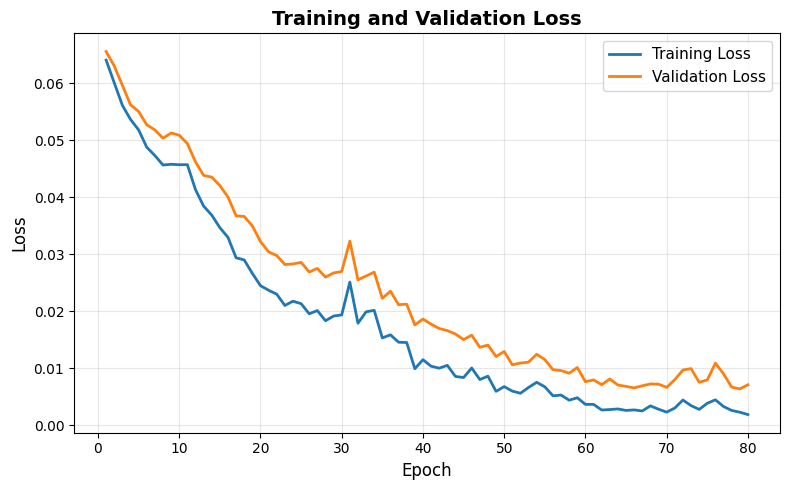

In [16]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9B — Training Loss Curve (v4 — NaN-safe, connected)     ║
# ╚══════════════════════════════════════════════════════════════╝
import matplotlib.pyplot as plt
import numpy as np

epochs_range = list(range(1, len(history) + 1))
train_loss   = [h['tl']   for h in history]
val_loss     = [h['vl']   for h in history]
train_acc    = [h['ta']   for h in history]
val_acc      = [h['va']   for h in history]
val_auc_list = [h['vauc'] for h in history]


def sanitize_curve(values):
    """
    Replace NaN/inf with the previous valid value so matplotlib
    draws a continuous line. If the very first value is NaN, use
    the next valid one.
    """
    arr = np.array(values, dtype=float)

    # Find first valid value to backfill any leading NaNs
    first_valid = next((v for v in arr if np.isfinite(v)), 0.0)

    cleaned   = []
    last_good = first_valid
    for v in arr:
        if np.isfinite(v):
            cleaned.append(v)
            last_good = v
        else:
            cleaned.append(last_good)   # carry forward last valid
    return cleaned


# Sanitize all curves so no lines have gaps
train_loss_clean = sanitize_curve(train_loss)
val_loss_clean   = sanitize_curve(val_loss)
train_acc_clean  = sanitize_curve(train_acc)
val_acc_clean    = sanitize_curve(val_acc)
val_auc_clean    = sanitize_curve(val_auc_list)


plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_loss_clean, label='Training Loss',
         linewidth=2, color='#1f77b4')
plt.plot(epochs_range, val_loss_clean,   label='Validation Loss',
         linewidth=2, color='#ff7f0e')
plt.xlabel('Epoch',  fontsize=12)
plt.ylabel('Loss',   fontsize=12)
plt.title('Training and Validation Loss', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Loss_Curve.png', dpi=600, bbox_inches='tight')
plt.show()


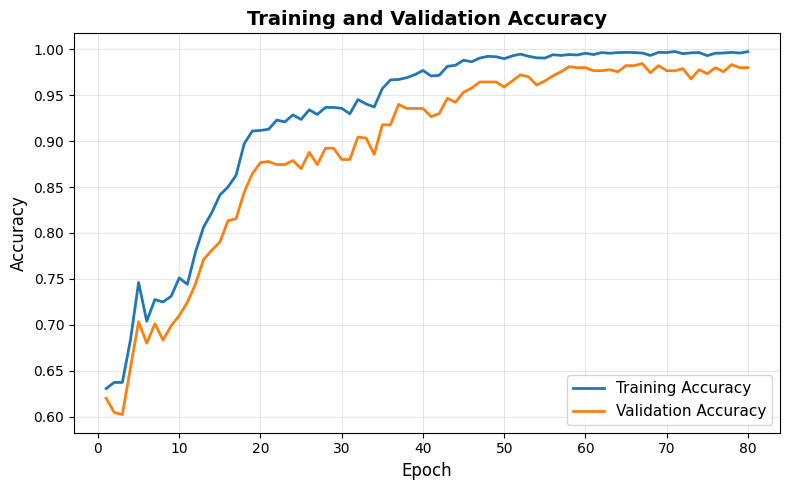

In [17]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9C — Training Accuracy Curve (v4 — NaN-safe, connected) ║
# ╚══════════════════════════════════════════════════════════════╝
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_acc_clean, label='Training Accuracy',
         linewidth=2, color='#1f77b4')
plt.plot(epochs_range, val_acc_clean,   label='Validation Accuracy',
         linewidth=2, color='#ff7f0e')
plt.xlabel('Epoch',    fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Accuracy_Curve.png', dpi=600, bbox_inches='tight')
plt.show()


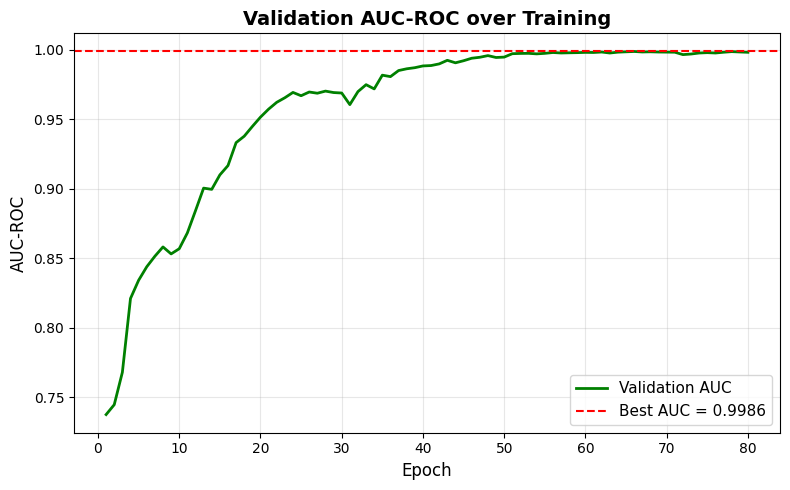

In [18]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9D — Validation AUC-ROC over Epochs (v4 — NaN-safe)     ║
# ╚══════════════════════════════════════════════════════════════╝
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, val_auc_clean, color='green', linewidth=2,
         label='Validation AUC')
plt.axhline(y=max(val_auc_clean), color='red', linestyle='--',
            label=f'Best AUC = {max(val_auc_clean):.4f}')
plt.xlabel('Epoch',    fontsize=12)
plt.ylabel('AUC-ROC',  fontsize=12)
plt.title('Validation AUC-ROC over Training', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Validation_AUC_Curve.png', dpi=600, bbox_inches='tight')
plt.show()


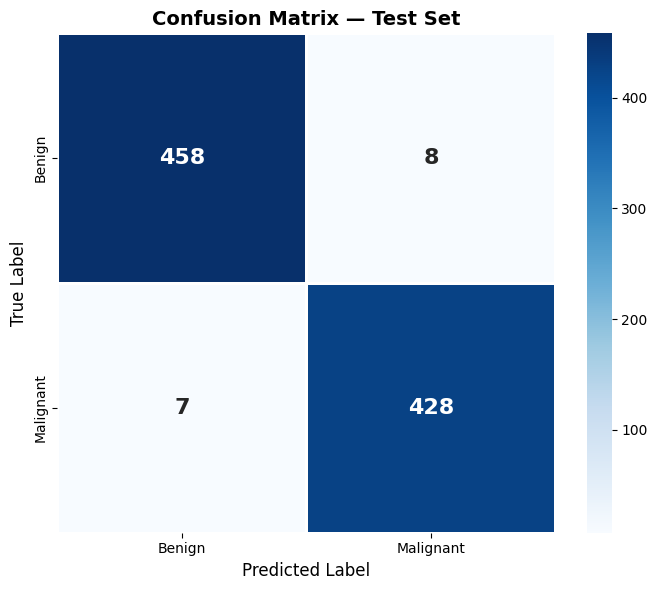


True Negatives  (Benign correct)    : 458
False Positives (Benign → Malignant) : 8
False Negatives (Malignant missed)   : 7
True Positives  (Malignant correct)  : 428

Sensitivity (Recall, Malignant) : 98.39%
Specificity (Recall, Benign)    : 98.28%
Precision (Malignant)           : 98.17%


In [19]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9E — Confusion Matrix (separate)                        ║
# ╚══════════════════════════════════════════════════════════════╝
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, predictions)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'],
            cbar=True, annot_kws={'size': 16, 'weight': 'bold'},
            linewidths=1, linecolor='white')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label',      fontsize=12)
plt.title('Confusion Matrix — Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Confusion_Matrix.png', dpi=600, bbox_inches='tight')
plt.show()

# Quick stats
tn, fp, fn, tp = cm.ravel()
print(f'\nTrue Negatives  (Benign correct)    : {tn}')
print(f'False Positives (Benign → Malignant) : {fp}')
print(f'False Negatives (Malignant missed)   : {fn}')
print(f'True Positives  (Malignant correct)  : {tp}')
print(f'\nSensitivity (Recall, Malignant) : {tp/(tp+fn)*100:.2f}%')
print(f'Specificity (Recall, Benign)    : {tn/(tn+fp)*100:.2f}%')
print(f'Precision (Malignant)           : {tp/(tp+fp)*100:.2f}%')


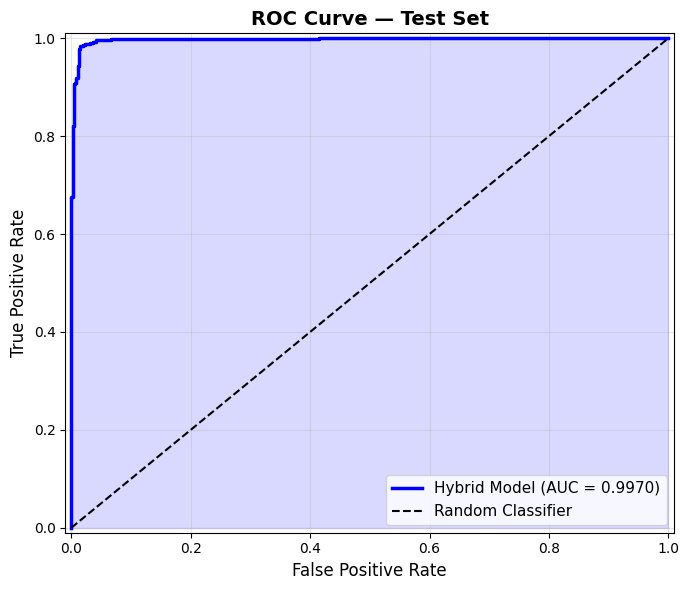

In [20]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9F — ROC Curve (separate)                               ║
# ╚══════════════════════════════════════════════════════════════╝
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(all_labels, all_probs)
roc_auc     = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='blue', linewidth=2.5,
         label=f'Hybrid Model (AUC = {roc_auc:.4f})')
plt.fill_between(fpr, tpr, alpha=0.15, color='blue')
plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.5,
         label='Random Classifier')
plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate',  fontsize=12)
plt.title('ROC Curve — Test Set', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ROC_Curve.png', dpi=600, bbox_inches='tight')
plt.show()


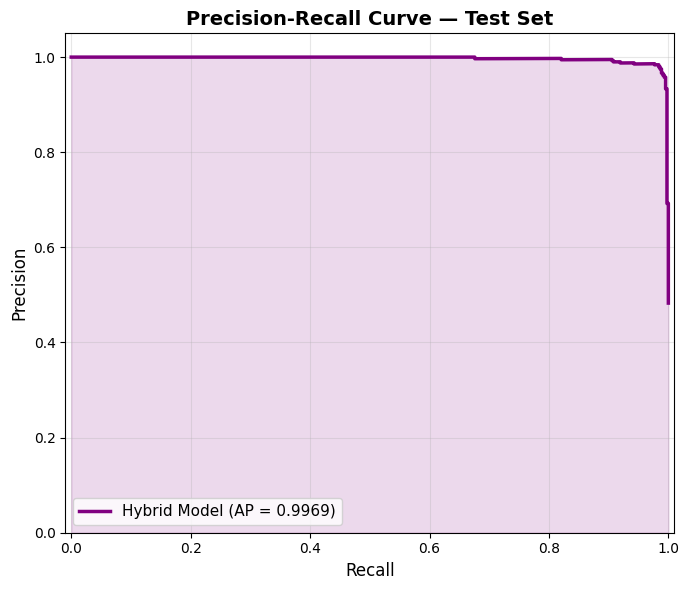

In [21]:
# ║ CELL 9G — Precision-Recall Curve (separate, BONUS)           ║
# ╚══════════════════════════════════════════════════════════════╝
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(all_labels, all_probs)
avg_precision        = average_precision_score(all_labels, all_probs)

plt.figure(figsize=(7, 6))
plt.plot(recall, precision, color='purple', linewidth=2.5,
         label=f'Hybrid Model (AP = {avg_precision:.4f})')
plt.fill_between(recall, precision, alpha=0.15, color='purple')
plt.xlabel('Recall',    fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve — Test Set', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower left')
plt.grid(True, alpha=0.3)
plt.xlim([-0.01, 1.01])
plt.ylim([0, 1.05])
plt.tight_layout()
plt.savefig('PR_Curve.png', dpi=600, bbox_inches='tight')
plt.show()


In [22]:
# ║ CELL 9H — Classification Report (text output)                ║
# ╚══════════════════════════════════════════════════════════════╝
from sklearn.metrics import classification_report

print('═' * 60)
print('CLASSIFICATION REPORT — Test Set')
print('═' * 60)
print(classification_report(all_labels, predictions,
                            target_names=['Benign', 'Malignant'],
                            digits=4))
print('═' * 60)
print(f'Test Accuracy : {test_acc*100:.2f}%')
print(f'Test AUC-ROC  : {test_auc:.4f}')
print('═' * 60)
print('\nAll plots saved as PNG (600 DPI) in working directory:')
print('  • Loss_Curve.png')
print('  • Accuracy_Curve.png')
print('  • Validation_AUC_Curve.png')
print('  • Confusion_Matrix.png')
print('  • ROC_Curve.png')
print('  • PR_Curve.png')

════════════════════════════════════════════════════════════
CLASSIFICATION REPORT — Test Set
════════════════════════════════════════════════════════════
              precision    recall  f1-score   support

      Benign     0.9849    0.9828    0.9839       466
   Malignant     0.9817    0.9839    0.9828       435

    accuracy                         0.9834       901
   macro avg     0.9833    0.9834    0.9833       901
weighted avg     0.9834    0.9834    0.9834       901

════════════════════════════════════════════════════════════
Test Accuracy : 98.34%
Test AUC-ROC  : 0.9970
════════════════════════════════════════════════════════════

All plots saved as PNG (600 DPI) in working directory:
  • Loss_Curve.png
  • Accuracy_Curve.png
  • Validation_AUC_Curve.png
  • Confusion_Matrix.png
  • ROC_Curve.png
  • PR_Curve.png


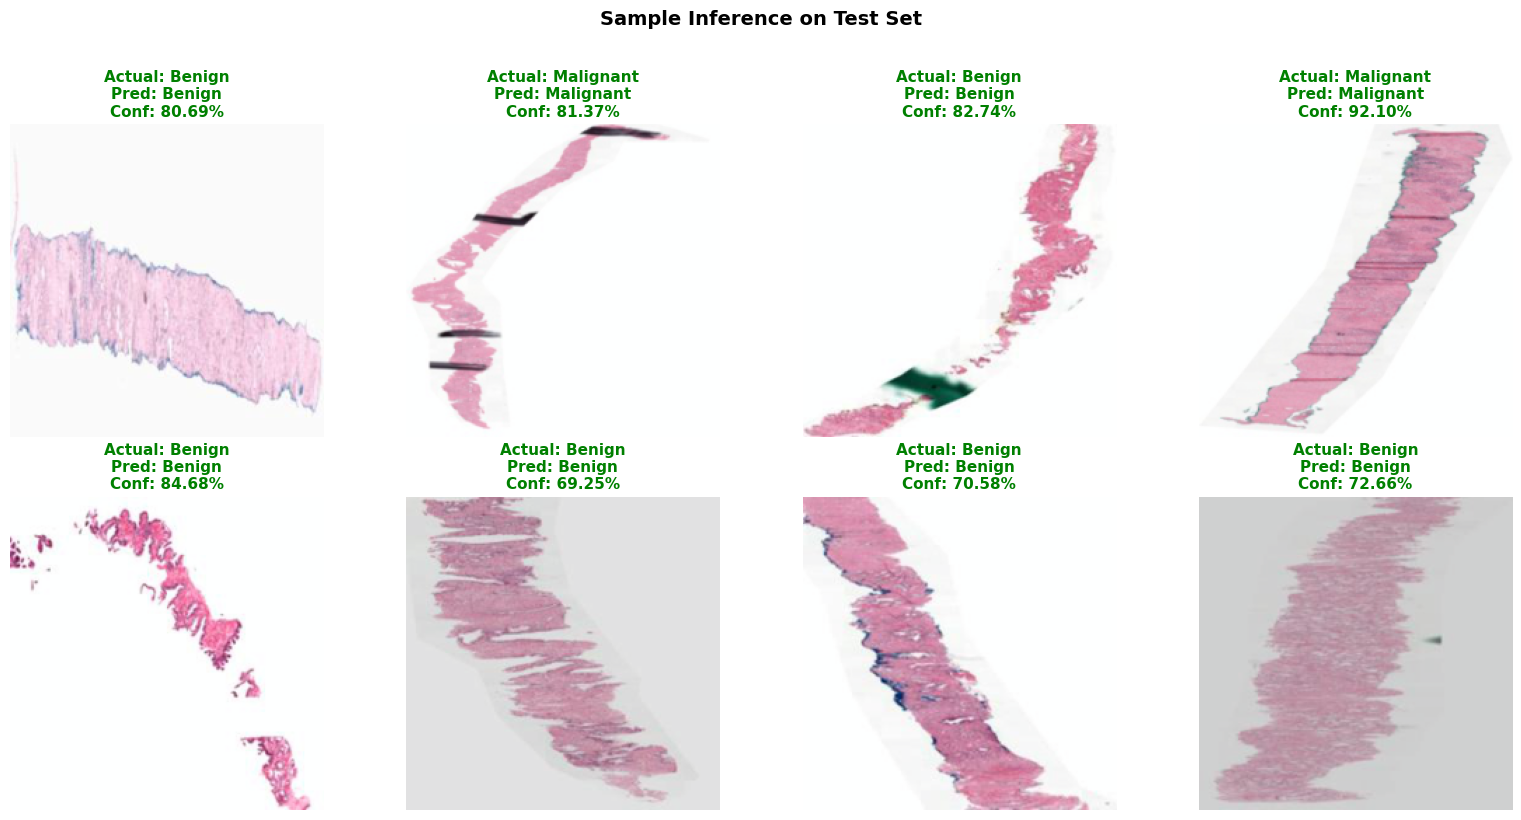


Visualized 8 random test samples
Saved to: Sample_Inference.png
Green title = correct prediction | Red title = incorrect


In [23]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9I — Sample Inference Visualization                     ║
# ║ Shows actual vs predicted labels with confidence on test set ║
# ╚══════════════════════════════════════════════════════════════╝
import matplotlib.pyplot as plt
import torch
import numpy as np
from PIL import Image

class_names = ['Benign', 'Malignant']

# ── Inference function ─────────────────────────────────────
def predict_single(model, img_tensor, graph):
    """Run model on one sample, return (predicted_class, confidence)."""
    model.eval()
    with torch.no_grad():
        img_tensor = img_tensor.unsqueeze(0).to(DEVICE)
        if graph is not None:
            from torch_geometric.data import Batch
            graph_batch = Batch.from_data_list([graph]).to(DEVICE)
        else:
            graph_batch = None

        with torch.cuda.amp.autocast():
            out = model(img_tensor, graph_batch)
        out   = out.float()
        probs = torch.softmax(out, dim=1)[0].cpu().numpy()

    pred_idx   = int(np.argmax(probs))
    confidence = float(probs[pred_idx])
    return pred_idx, confidence


# ── De-normalize image for display (reverse ImageNet stats) ─
def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.cpu().numpy().transpose(1, 2, 0)
    img  = img * std + mean
    img  = np.clip(img, 0, 1)
    return img


# ── Pick 8 random test samples and visualize ───────────────
np.random.seed(42)
n_show         = 8
sample_indices = np.random.choice(len(test_ds), n_show, replace=False)

plt.figure(figsize=(16, 8))

for i, idx in enumerate(sample_indices):
    img_tensor, label, graph = test_ds[idx]

    pred_idx, confidence = predict_single(model, img_tensor, graph)

    actual_class    = class_names[int(label)]
    predicted_class = class_names[pred_idx]
    is_correct      = (pred_idx == int(label))

    # Display
    ax = plt.subplot(2, 4, i + 1)
    img_display = denormalize(img_tensor)
    ax.imshow(img_display)
    ax.axis('off')

    title_color = 'green' if is_correct else 'red'
    ax.set_title(
        f'Actual: {actual_class}\n'
        f'Pred: {predicted_class}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11,
        color=title_color,
        fontweight='bold'
    )

plt.suptitle('Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Sample_Inference.png', dpi=600, bbox_inches='tight')
plt.show()

print(f'\nVisualized {n_show} random test samples')
print(f'Saved to: Sample_Inference.png')
print(f'Green title = correct prediction | Red title = incorrect')

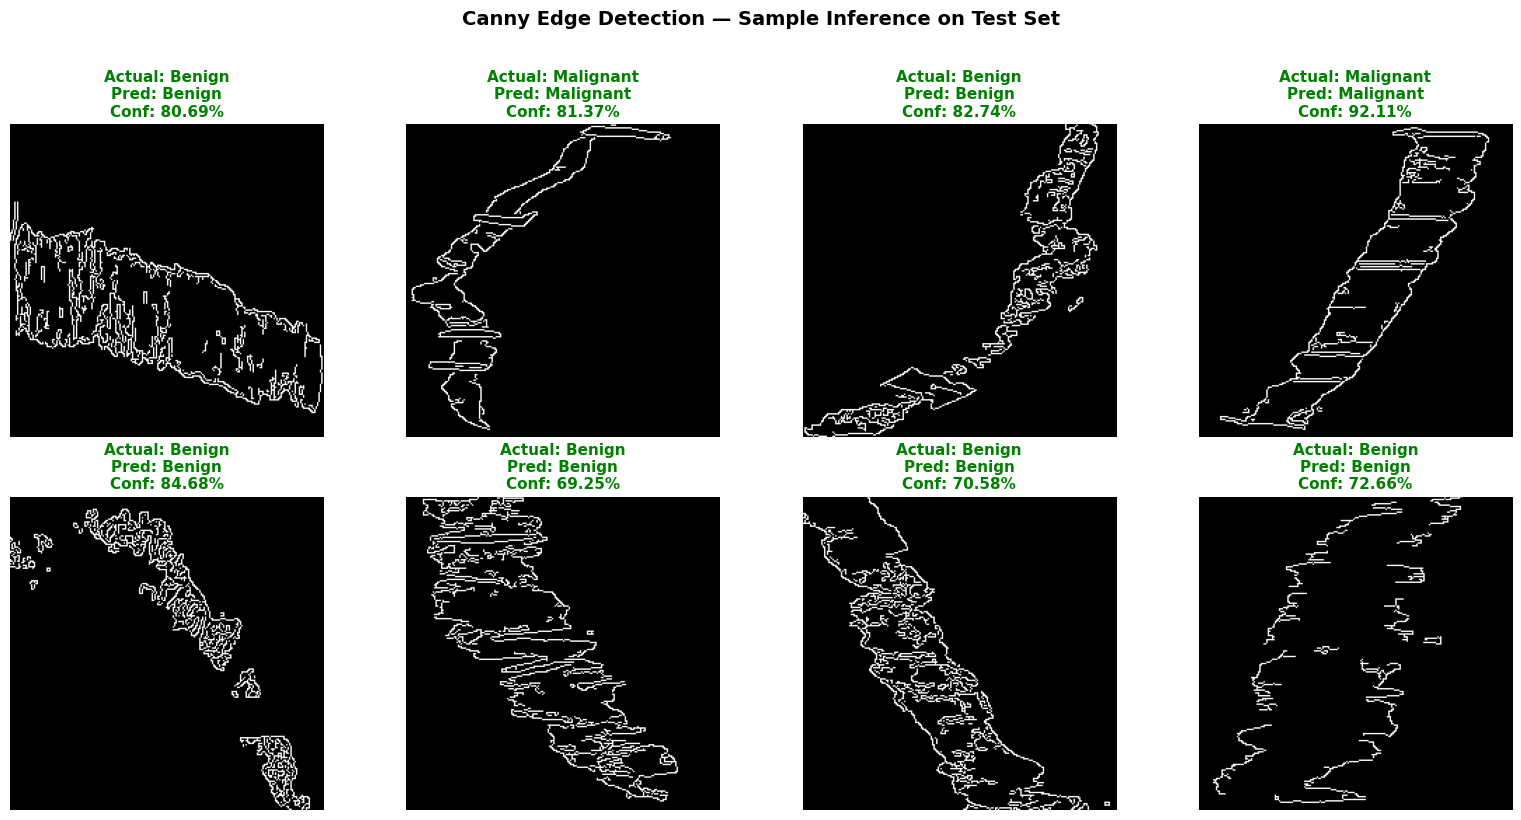


Canny edge maps for 8 random test samples
Saved to: Canny_Edge_Inference.png
Green title = correct prediction | Red title = incorrect


In [24]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9J — Canny Edge Detection on Sample Inference Images    ║
# ║ Shows edge maps for the same 8 test samples from Cell 9I     ║
# ╚══════════════════════════════════════════════════════════════╝
import cv2
import matplotlib.pyplot as plt   # ← add this line
import numpy as np

plt.figure(figsize=(16, 8))

for i, idx in enumerate(sample_indices):   # reuses sample_indices from Cell 9I
    img_tensor, label, graph = test_ds[idx]

    pred_idx, confidence = predict_single(model, img_tensor, graph)

    actual_class    = class_names[int(label)]
    predicted_class = class_names[pred_idx]
    is_correct      = (pred_idx == int(label))

    # ── Denormalize → uint8 → grayscale → Canny ────────────
    img_display = denormalize(img_tensor)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    edges       = cv2.Canny(img_gray, threshold1=50, threshold2=150)

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(edges, cmap='gray')
    ax.axis('off')

    title_color = 'green' if is_correct else 'red'
    ax.set_title(
        f'Actual: {actual_class}\n'
        f'Pred: {predicted_class}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11,
        color=title_color,
        fontweight='bold'
    )

plt.suptitle('Canny Edge Detection — Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Canny_Edge_Inference.png', dpi=600, bbox_inches='tight')
plt.show()

print(f'\nCanny edge maps for {n_show} random test samples')
print(f'Saved to: Canny_Edge_Inference.png')
print(f'Green title = correct prediction | Red title = incorrect')

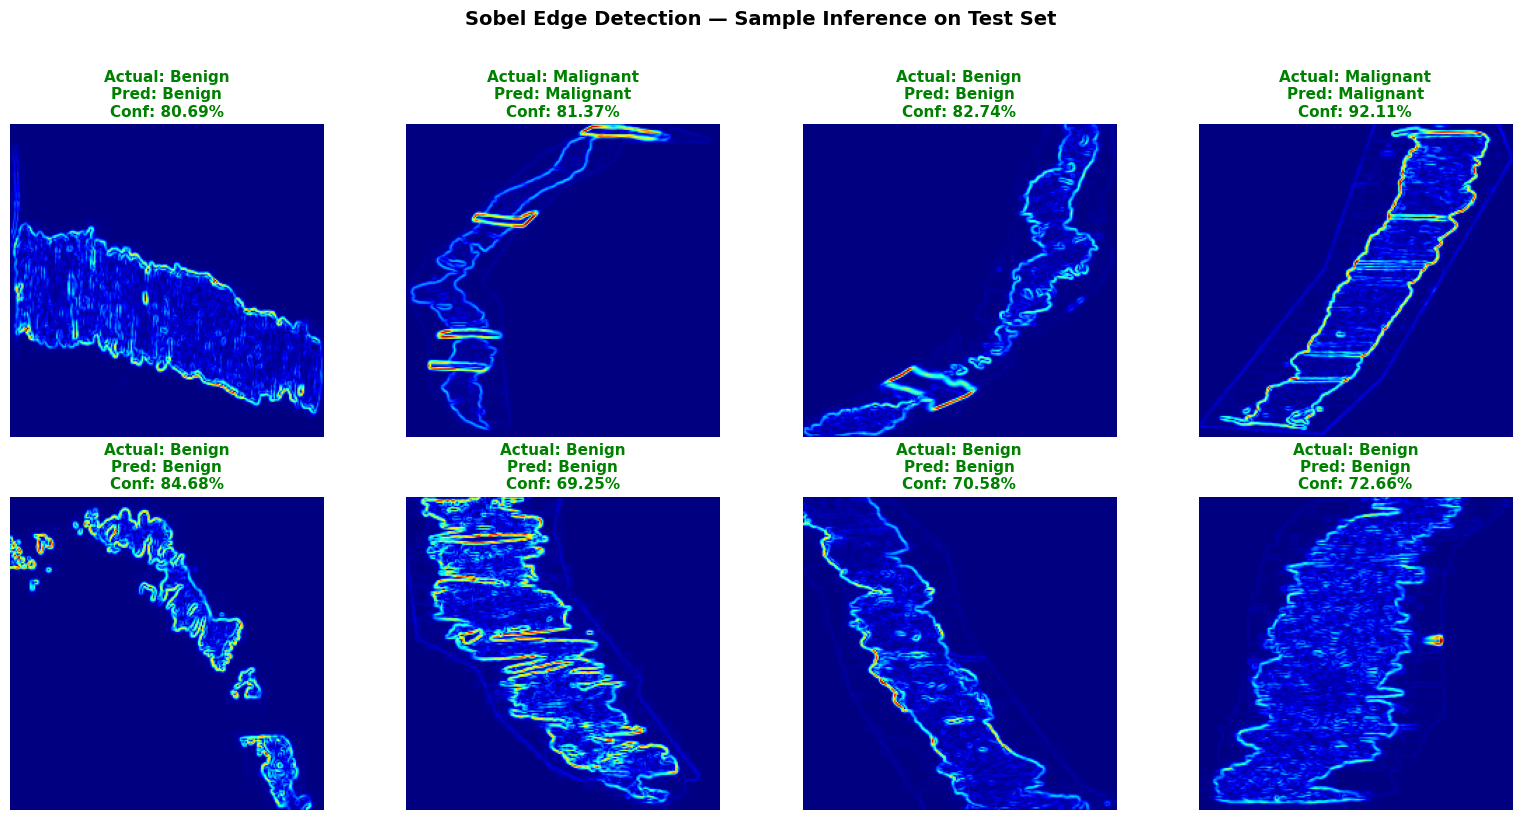


Sobel edge maps for 8 random test samples
Saved to: Sobel_Edge_Inference.png
Green title = correct prediction | Red title = incorrect


In [25]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9K — Sobel Edge Detection on Sample Inference Images    ║
# ╚══════════════════════════════════════════════════════════════╝
import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(16, 8))

n_show         = 8
np.random.seed(42)                                          # same seed = same 8 images as Canny
sample_indices = np.random.choice(len(test_ds), n_show, replace=False)

for i, idx in enumerate(sample_indices):
    img_tensor, label, graph = test_ds[idx]

    pred_idx, confidence = predict_single(model, img_tensor, graph)

    actual_class    = class_names[int(label)]
    predicted_class = class_names[pred_idx]
    is_correct      = (pred_idx == int(label))

    # ── Denormalize → uint8 → grayscale → Sobel ────────────
    img_display = denormalize(img_tensor)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)

    sobel_x     = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y     = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    magnitude   = cv2.magnitude(sobel_x, sobel_y)
    mag_norm    = cv2.normalize(magnitude, None, 0, 255,
                                cv2.NORM_MINMAX, cv2.CV_8U)
    edges_bgr   = cv2.applyColorMap(mag_norm, cv2.COLORMAP_JET)
    edges_rgb   = cv2.cvtColor(edges_bgr, cv2.COLOR_BGR2RGB)

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(edges_rgb)
    ax.axis('off')

    title_color = 'green' if is_correct else 'red'
    ax.set_title(
        f'Actual: {actual_class}\n'
        f'Pred: {predicted_class}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11, color=title_color, fontweight='bold'
    )

plt.suptitle('Sobel Edge Detection — Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Sobel_Edge_Inference.png', dpi=600, bbox_inches='tight')
plt.show()

print(f'\nSobel edge maps for {n_show} random test samples')
print(f'Saved to: Sobel_Edge_Inference.png')
print(f'Green title = correct prediction | Red title = incorrect')

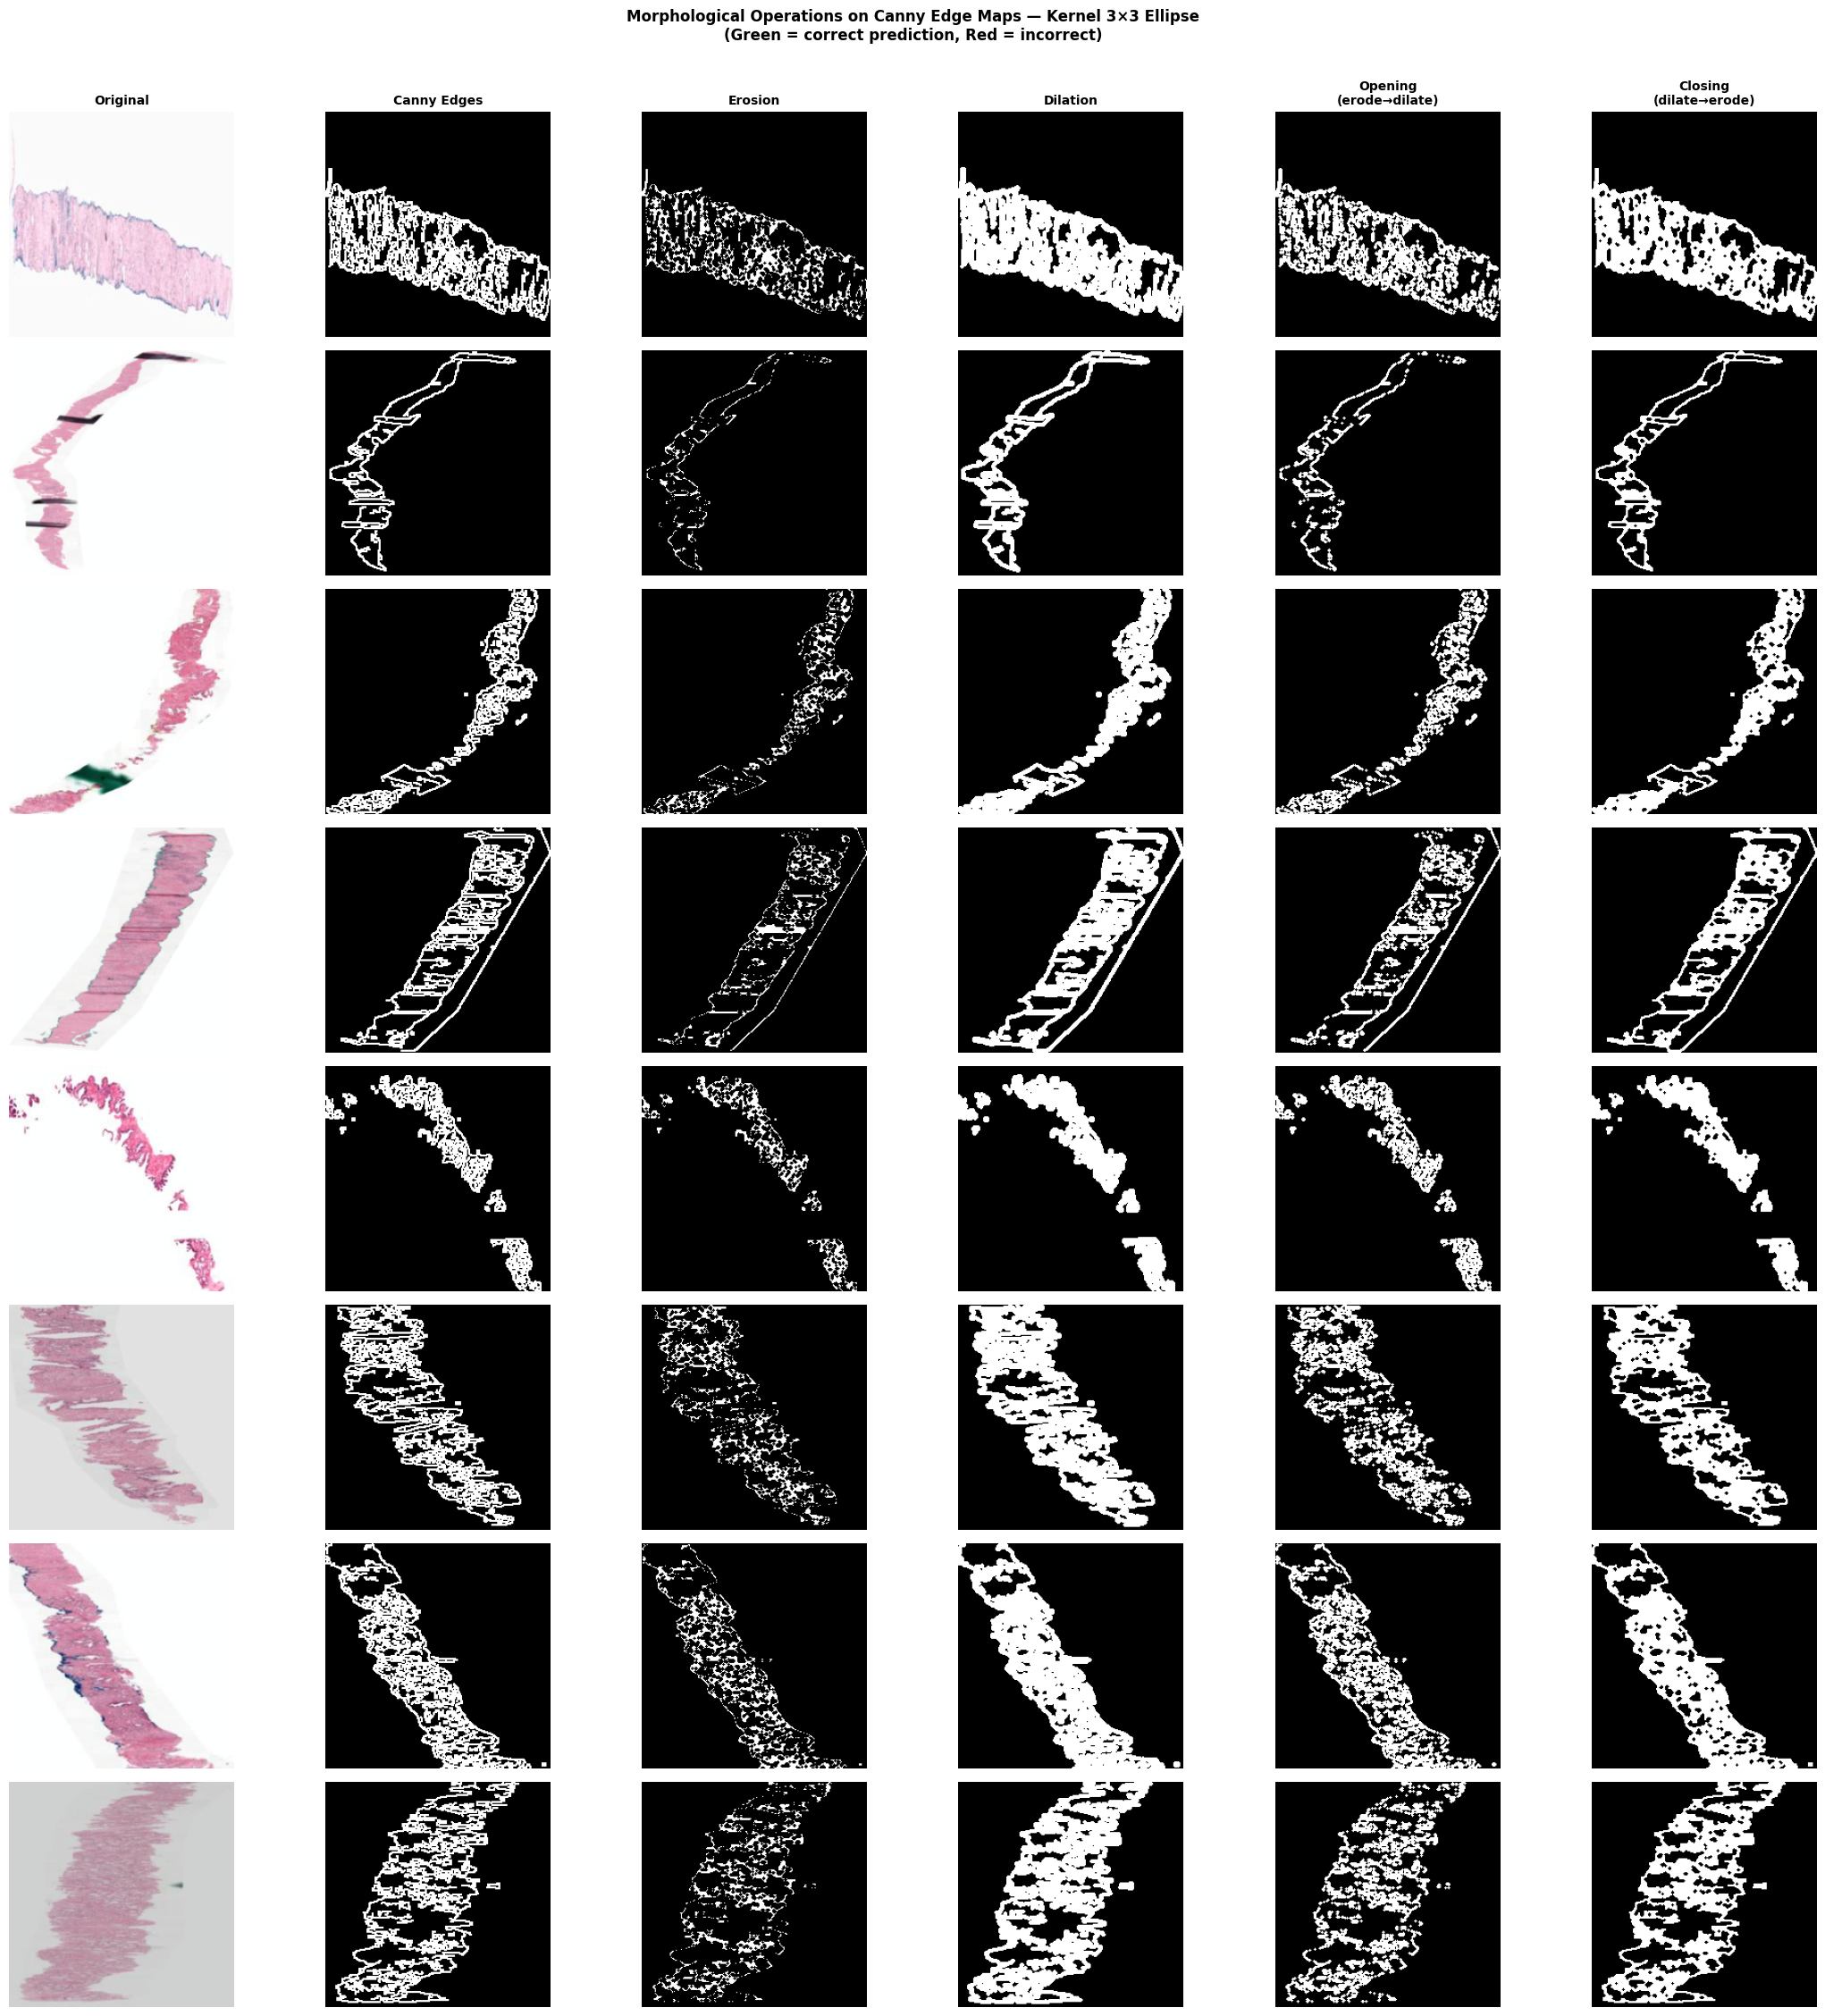

Saved to: Morphological_Canny02.png


In [26]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9L — Morphological Operations on Canny Edge Maps (v2)   ║
# ║ Fix: pre-dilate edges to 2-3px thick before morphology       ║
# ╚══════════════════════════════════════════════════════════════╝
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ── Kernels ──────────────────────────────────────────────────
pre_kernel = cv2.getStructuringElement(cv2.MORPH_RECT,    (2, 2))
kernel     = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

n_show         = 8
np.random.seed(42)
sample_indices = np.random.choice(len(test_ds), n_show, replace=False)

fig, axes = plt.subplots(n_show, 6, figsize=(22, n_show * 2.8))
col_titles = ['Original', 'Canny Edges', 'Erosion', 'Dilation',
              'Opening\n(erode→dilate)', 'Closing\n(dilate→erode)']

for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=10, fontweight='bold')

for row, idx in enumerate(sample_indices):
    img_tensor, label, graph = test_ds[idx]
    pred_idx, confidence     = predict_single(model, img_tensor, graph)

    actual_class    = class_names[int(label)]
    predicted_class = class_names[pred_idx]
    is_correct      = (pred_idx == int(label))
    color           = 'green' if is_correct else 'red'

    # ── Preprocess ───────────────────────────────────────────
    img_display = denormalize(img_tensor)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)

    # ── Canny → pre-thicken to survive erosion ───────────────
    edges     = cv2.Canny(img_gray, threshold1=30, threshold2=100)
    edges     = cv2.dilate(edges, pre_kernel, iterations=1)

    # ── Morphological operations ─────────────────────────────
    eroded  = cv2.erode(edges,  kernel, iterations=1)
    dilated = cv2.dilate(edges, kernel, iterations=1)
    opened  = cv2.morphologyEx(edges, cv2.MORPH_OPEN,  kernel)
    closed  = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

    for col, (img, cmap) in enumerate([
        (img_display, None  ),
        (edges,       'gray'),
        (eroded,      'gray'),
        (dilated,     'gray'),
        (opened,      'gray'),
        (closed,      'gray'),
    ]):
        ax = axes[row, col]
        ax.imshow(img, cmap=cmap)
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(
                f'A:{actual_class}\nP:{predicted_class}\n{confidence*100:.1f}%',
                fontsize=7, color=color, rotation=0,
                labelpad=85, va='center'
            )

plt.suptitle(
    'Morphological Operations on Canny Edge Maps — Kernel 3×3 Ellipse\n'
    '(Green = correct prediction, Red = incorrect)',
    fontsize=12, fontweight='bold', y=1.005
)
plt.tight_layout()
plt.savefig('Morphological_Canny.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved to: Morphological_Canny02.png')

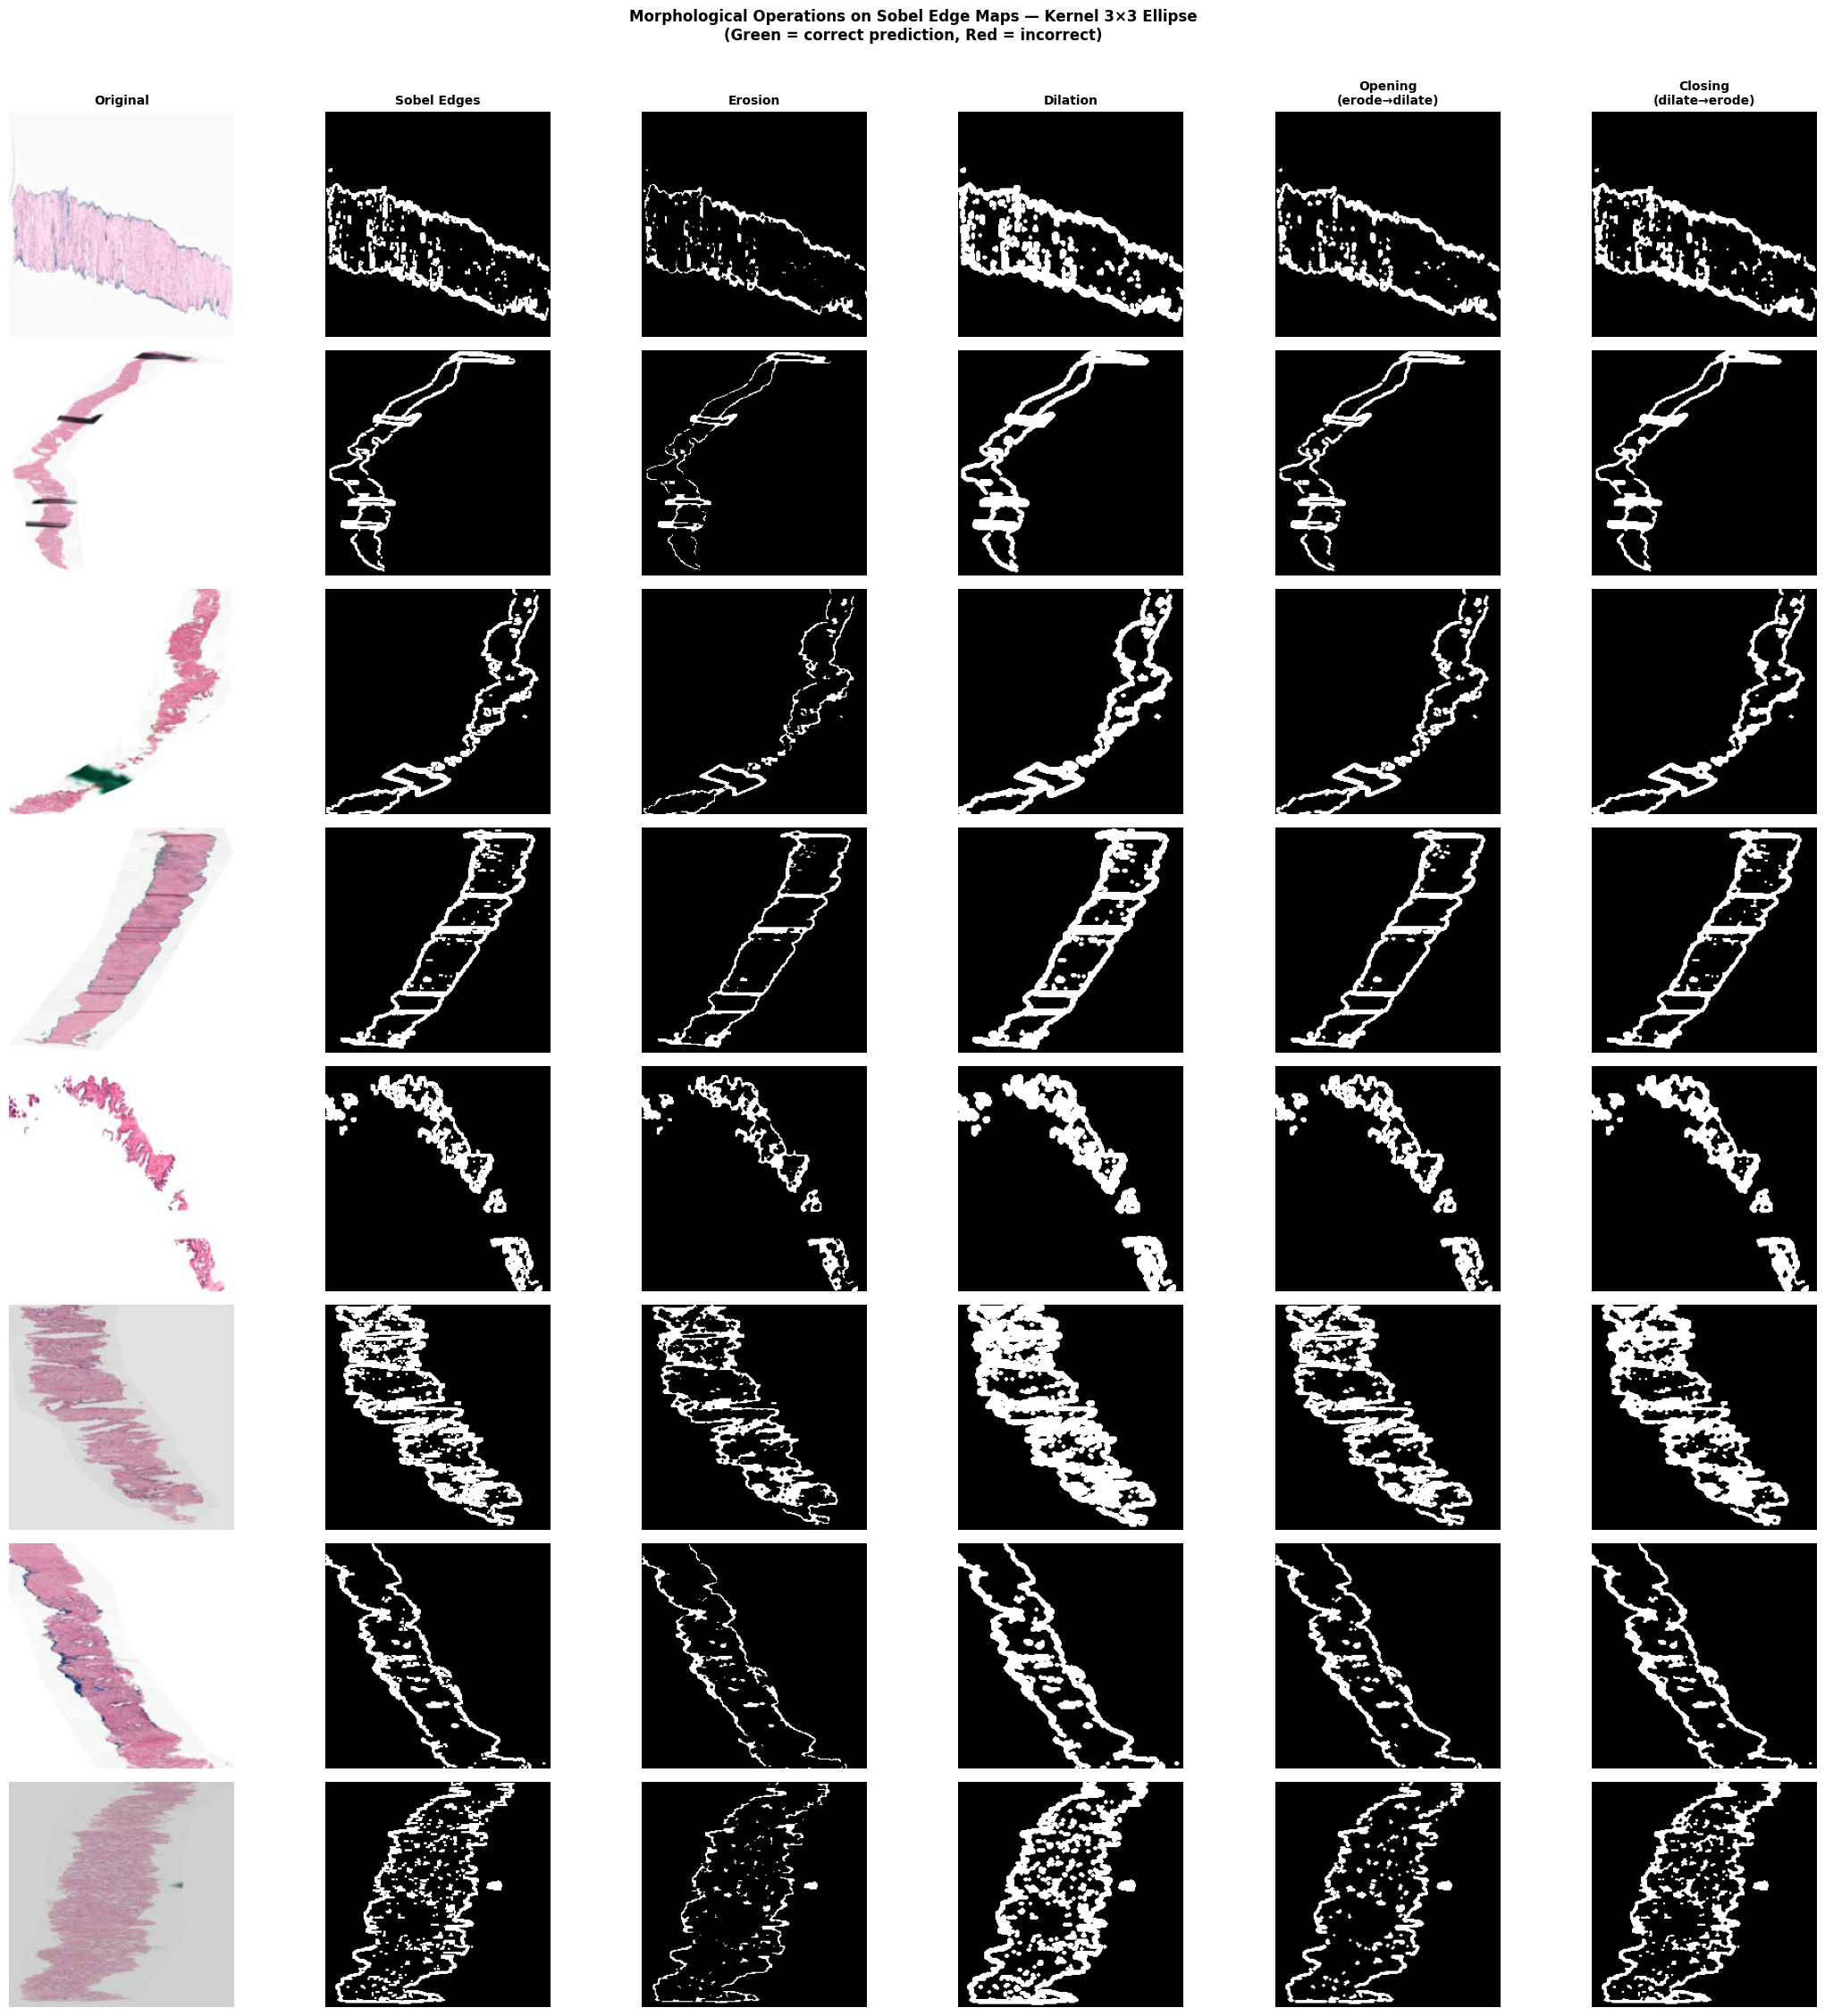

Saved to: Morphological_Sobel.png


In [27]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9M — Morphological Operations on Sobel Edge Maps        ║
# ╚══════════════════════════════════════════════════════════════╝
import cv2
import numpy as np
import matplotlib.pyplot as plt

pre_kernel = cv2.getStructuringElement(cv2.MORPH_RECT,    (2, 2))
kernel     = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

n_show         = 8
np.random.seed(42)
sample_indices = np.random.choice(len(test_ds), n_show, replace=False)

fig, axes = plt.subplots(n_show, 6, figsize=(22, n_show * 2.8))
col_titles = ['Original', 'Sobel Edges', 'Erosion', 'Dilation',
              'Opening\n(erode→dilate)', 'Closing\n(dilate→erode)']

for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=10, fontweight='bold')

for row, idx in enumerate(sample_indices):
    img_tensor, label, graph = test_ds[idx]
    pred_idx, confidence     = predict_single(model, img_tensor, graph)

    actual_class    = class_names[int(label)]
    predicted_class = class_names[pred_idx]
    is_correct      = (pred_idx == int(label))
    color           = 'green' if is_correct else 'red'

    img_display = denormalize(img_tensor)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)

    # ── Sobel → magnitude → normalize → threshold → binary ──
    sobel_x   = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y   = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = cv2.magnitude(sobel_x, sobel_y)
    mag_norm  = cv2.normalize(magnitude, None, 0, 255,
                              cv2.NORM_MINMAX, cv2.CV_8U)

    # Threshold to binary (same role as Canny's binary output)
    _, edges = cv2.threshold(mag_norm, 50, 255, cv2.THRESH_BINARY)

    # Pre-thicken so erosion survives
    edges = cv2.dilate(edges, pre_kernel, iterations=1)

    # ── Morphological operations ─────────────────────────────
    eroded  = cv2.erode(edges,  kernel, iterations=1)
    dilated = cv2.dilate(edges, kernel, iterations=1)
    opened  = cv2.morphologyEx(edges, cv2.MORPH_OPEN,  kernel)
    closed  = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

    for col, (img, cmap) in enumerate([
        (img_display, None  ),
        (edges,       'gray'),
        (eroded,      'gray'),
        (dilated,     'gray'),
        (opened,      'gray'),
        (closed,      'gray'),
    ]):
        ax = axes[row, col]
        ax.imshow(img, cmap=cmap)
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(
                f'A:{actual_class}\nP:{predicted_class}\n{confidence*100:.1f}%',
                fontsize=7, color=color, rotation=0,
                labelpad=85, va='center'
            )

plt.suptitle(
    'Morphological Operations on Sobel Edge Maps — Kernel 3×3 Ellipse\n'
    '(Green = correct prediction, Red = incorrect)',
    fontsize=12, fontweight='bold', y=1.005
)
plt.tight_layout()
plt.savefig('Morphological_Sobel.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved to: Morphological_Sobel.png')

## CELL 10 — Results Summary

In [28]:
# ══════════════════════════════════════════════════════════════════
# CELL 10 — Final Metrics
# ══════════════════════════════════════════════════════════════════
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             precision_score, matthews_corrcoef)

accuracy  = accuracy_score(all_labels, predictions)
f1        = f1_score(all_labels, predictions, average='weighted')
recall    = recall_score(all_labels, predictions, average='weighted')
precision = precision_score(all_labels, predictions, average='weighted')
mcc       = matthews_corrcoef(all_labels, predictions)

print("Accuracy : ", accuracy)
print("F1 Score : ", f1)
print("Recall   : ", recall)
print("Precision: ", precision)
print("MCC      : ", mcc)
print("AUC-ROC  : ", test_auc)

Accuracy :  0.9833518312985572
F1 Score :  0.9833524472122891
Recall   :  0.9833518312985572
Precision:  0.9833554881913567
MCC      :  0.9666691357081877
AUC-ROC  :  0.9969611760643282


## CELL 12 — Save All Results 


In [29]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ Save all results to local Result folder                       ║
# ║   <repo>\Result\                                    ║
# ╚══════════════════════════════════════════════════════════════╝
import os, shutil

OUT_DIR = os.path.join(WORK_DIR, 'Result')
os.makedirs(OUT_DIR, exist_ok=True)

artifacts = [
    'Loss_Curve.png',
    'Accuracy_Curve.png',
    'Validation_AUC_Curve.png',
    'Confusion_Matrix.png',
    'ROC_Curve.png',
    'PR_Curve.png',
    'Sample_Inference.png',
]

saved = []
for f in artifacts:
    if os.path.exists(f):
        dst = os.path.join(OUT_DIR, f)
        shutil.copy(f, dst)
        saved.append(dst)

# Also copy the best model checkpoint
if os.path.exists(MODEL_PATH):
    dst = os.path.join(OUT_DIR, 'best_hybrid_model.pth')
    shutil.copy(MODEL_PATH, dst)
    saved.append(dst)

print(f'All results saved to {OUT_DIR}:')
for s in saved:
    print('  •', os.path.basename(s))


All results saved to <repo>/results\Retrain\Result:
  • Loss_Curve.png
  • Accuracy_Curve.png
  • Validation_AUC_Curve.png
  • Confusion_Matrix.png
  • ROC_Curve.png
  • PR_Curve.png
  • Sample_Inference.png
  • best_hybrid_model.pth


## Results Summary

### Architecture Novelty 
- **CNN branch**: EfficientNet-B4 captures local texture features
- **GAT branch**: Graph Attention captures long-range inter-patch relationships with learnable attention weights
- **GCN branch**: Graph Convolution captures local tissue topology from SLIC superpixels
- **Fusion**: All three branches concatenated for complementary feature integration

### Hyperparameters to report in 
```
Backbone        : EfficientNet-B4 (ImageNet pretrained)
GAT heads       : 4
Hidden dim      : 256
Optimizer       : AdamW (backbone LR=1e-4, head LR=3e-4)
Scheduler       : CosineAnnealingWarmRestarts (T0=10)
Loss            : CrossEntropy + Label Smoothing (0.1)
Augmentation    : RandomFlip, Rotation, ColorJitter, MixUp, RandomErasing
Batch size      : 32
Max epochs      : 50
Early stopping  : patience=10
Mixed precision : AMP (float16)
```


In [3]:
# ═══════════════════════════════════════════════════════════════════════
# ALIGNMENT CELL — Hybrid notebook only
# Save non-TTA predictions with file paths so a cross-notebook McNemar test
# can align every model to the same sample order.
#
# ► Add as a NEW cell after Cell 8B in Proposed_Hybrid_Prostate_.ipynb.
# ► Requires: model, test_ds, test_loader, MODEL_PATH, WORK_DIR, DEVICE
# ► Run once. Saves ONE file: hybrid_aligned_raw.npz
# ═══════════════════════════════════════════════════════════════════════
MODEL_PATH = os.path.join(WORK_DIR, 'best_hybrid_model_v2.pth')
import os, numpy as np, torch

# Reload best checkpoint (safety in case classifier was modified later)
ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

# File paths in the exact order test_loader iterates (shuffle=False)
paths = [test_ds.files[i][0] for i in range(len(test_ds))]

y_prob_all, y_pred_all, y_true_all = [], [], []
with torch.no_grad():
    for imgs, lbls, graphs in test_loader:      # Hybrid collate order
        imgs   = imgs.to(DEVICE, non_blocking=True)
        graphs = graphs.to(DEVICE)
        out    = model(imgs, graphs)
        probs  = torch.softmax(out.float(), dim=1)[:, 1]
        probs  = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds  = (probs >= 0.5).long()
        y_prob_all.extend(probs.cpu().numpy().tolist())
        y_pred_all.extend(preds.cpu().numpy().tolist())
        y_true_all.extend(lbls.numpy().tolist())

y_prob = np.array(y_prob_all)
y_pred = np.array(y_pred_all)
y_true = np.array(y_true_all)
assert len(paths) == len(y_true), \
    f'path/pred length mismatch: {len(paths)} vs {len(y_true)}'

out_path = os.path.join(WORK_DIR, 'hybrid_aligned_raw.npz')
np.savez(
    out_path,
    file_paths = np.array(paths),
    y_true     = y_true,
    y_pred     = y_pred,
    y_prob     = y_prob,
)
print(f'Saved {len(paths)} predictions with paths to:')
print(f'  {out_path}')
print(f'Sanity check — accuracy: {(y_pred == y_true).mean() * 100:.2f}%')


NameError: name 'WORK_DIR' is not defined